# Olist EDA


In [2]:
import pandas as pd
import numpy
from pathlib import Path


In [3]:
SEED = 14

In [4]:
data_customers = pd.read_csv("../data/raw/olist_customers_dataset.csv")
data_products = pd.read_csv("../data/raw/olist_products_dataset.csv")
data_sellers = pd.read_csv("../data/raw/olist_sellers_dataset.csv")
data_geolocation = pd.read_csv("../data/raw/olist_geolocation_dataset.csv")
data_orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")
data_payments = pd.read_csv("../data/raw/olist_order_payments_dataset.csv")
data_order_items = pd.read_csv("../data/raw/olist_order_items_dataset.csv")

In [5]:
data_order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [6]:

order_with_products = data_order_items.merge(data_products, on="product_id", how="left",validate="many_to_one",indicator=True)
orders_with_customers = data_orders.merge(data_customers, on="customer_id", how="left",validate="many_to_one",indicator=True)
# data_all = orders_with_customers.merge(order_with_products, on="order_id", how="left",validate="many_to_one",indicator=True)
items_with_order_details = (order_with_products.drop(columns="_merge").merge( 
    orders_with_customers.drop(columns="_merge"),
    on="order_id",
    how="left",
    validate="many_to_one",
    indicator=True
))

In [7]:
items_with_order_details.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 27 columns):
 #   Column                         Non-Null Count   Dtype   
---  ------                         --------------   -----   
 0   order_id                       112650 non-null  str     
 1   order_item_id                  112650 non-null  int64   
 2   product_id                     112650 non-null  str     
 3   seller_id                      112650 non-null  str     
 4   shipping_limit_date            112650 non-null  str     
 5   price                          112650 non-null  float64 
 6   freight_value                  112650 non-null  float64 
 7   product_category_name          111047 non-null  str     
 8   product_name_lenght            111047 non-null  float64 
 9   product_description_lenght     111047 non-null  float64 
 10  product_photos_qty             111047 non-null  float64 
 11  product_weight_g               112632 non-null  float64 
 12  product_length_cm          

In [8]:
ids = ["customer_id", "order_id", "product_id", "order_item_id", "customer_unique_id", "seller_id"]
other = ["_merge"]

columns_to_delete = ids + other
cleared_data = items_with_order_details.drop(columns_to_delete, axis=1)
cleared_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 20 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   shipping_limit_date            112650 non-null  str    
 1   price                          112650 non-null  float64
 2   freight_value                  112650 non-null  float64
 3   product_category_name          111047 non-null  str    
 4   product_name_lenght            111047 non-null  float64
 5   product_description_lenght     111047 non-null  float64
 6   product_photos_qty             111047 non-null  float64
 7   product_weight_g               112632 non-null  float64
 8   product_length_cm              112632 non-null  float64
 9   product_height_cm              112632 non-null  float64
 10  product_width_cm               112632 non-null  float64
 11  order_status                   112650 non-null  str    
 12  order_purchase_timestamp       112650 non

In [9]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
    "shipping_limit_date",
  
]

for column in date_columns:
    cleared_data[column] = pd.to_datetime(
        cleared_data[column],
        errors="raise",
    )

In [10]:
cleared_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 20 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   shipping_limit_date            112650 non-null  datetime64[us]
 1   price                          112650 non-null  float64       
 2   freight_value                  112650 non-null  float64       
 3   product_category_name          111047 non-null  str           
 4   product_name_lenght            111047 non-null  float64       
 5   product_description_lenght     111047 non-null  float64       
 6   product_photos_qty             111047 non-null  float64       
 7   product_weight_g               112632 non-null  float64       
 8   product_length_cm              112632 non-null  float64       
 9   product_height_cm              112632 non-null  float64       
 10  product_width_cm               112632 non-null  float64       
 11  order_statu

In [58]:
cleared_data["approval_duration_hours"] = (
    cleared_data["order_approved_at"] - cleared_data["order_purchase_timestamp"]
).dt.total_seconds() / 3600
cleared_data["actual_delivery_duration_days"] = (
    cleared_data["order_delivered_customer_date"] - cleared_data["order_approved_at"]
).dt.total_seconds() / 86400

cleared_data["delay_days"] = (
    cleared_data["order_delivered_customer_date"].dt.normalize()
    - cleared_data["order_estimated_delivery_date"].dt.normalize()
).dt.days

cleared_data["estimated_delivery_time"] = (cleared_data["order_estimated_delivery_date"] - cleared_data["order_approved_at"]).dt.total_seconds() / 86400
cleared_data["estimated_delivery_time"] = (cleared_data["order_estimated_delivery_date"] - cleared_data["order_purchase_timestamp"]).dt.total_seconds() / 86400
cleared_data["overdue_days"] = cleared_data["delay_days"].clip(lower=0)

In [59]:
cleared_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 108643 entries, 0 to 108642
Data columns (total 25 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   shipping_limit_date            108643 non-null  datetime64[us]
 1   price                          108643 non-null  float64       
 2   freight_value                  108643 non-null  float64       
 3   product_category_name          108643 non-null  str           
 4   product_name_lenght            108643 non-null  float64       
 5   product_description_lenght     108643 non-null  float64       
 6   product_photos_qty             108643 non-null  float64       
 7   product_weight_g               108643 non-null  float64       
 8   product_length_cm              108643 non-null  float64       
 9   product_height_cm              108643 non-null  float64       
 10  product_width_cm               108643 non-null  float64       
 11  order_statu

In [60]:
print(cleared_data.isna().sum())
cleared_data = cleared_data.dropna(ignore_index=True)

shipping_limit_date              0
price                            0
freight_value                    0
product_category_name            0
product_name_lenght              0
product_description_lenght       0
product_photos_qty               0
product_weight_g                 0
product_length_cm                0
product_height_cm                0
product_width_cm                 0
order_status                     0
order_purchase_timestamp         0
order_approved_at                0
order_delivered_carrier_date     0
order_delivered_customer_date    0
order_estimated_delivery_date    0
customer_zip_code_prefix         0
customer_city                    0
customer_state                   0
approval_duration_hours          0
actual_delivery_duration_days    0
delay_days                       0
overdue_days                     0
estimated_delivery_time          0
dtype: int64


In [ ]:
numeric_features = [
    "price",
    "freight_value",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm",
    "approval_duration_hours",
    "overdue_days",
    "customer_zip_code_prefix", 
    "approval_duration_hours",
    "estimated_delivery_time"
]

categorical_features = [
    "product_category_name",
    "customer_state",
]

In [54]:
baseline_data = cleared_data[numeric_features + categorical_features]

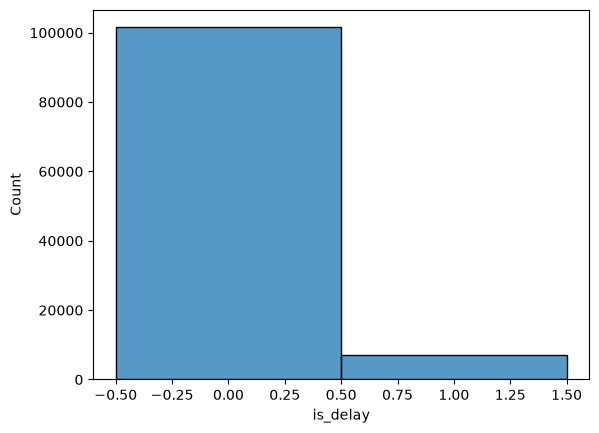

In [55]:
import seaborn as sns
import matplotlib.pyplot as plt

baseline_data["is_delay"] = (baseline_data["overdue_days"] > 0 ).astype(int)


baseline_data_non_zero = baseline_data.loc[baseline_data["overdue_days"] > 0].copy()
sns.histplot(x=baseline_data["is_delay"], discrete=True)

plt.show()

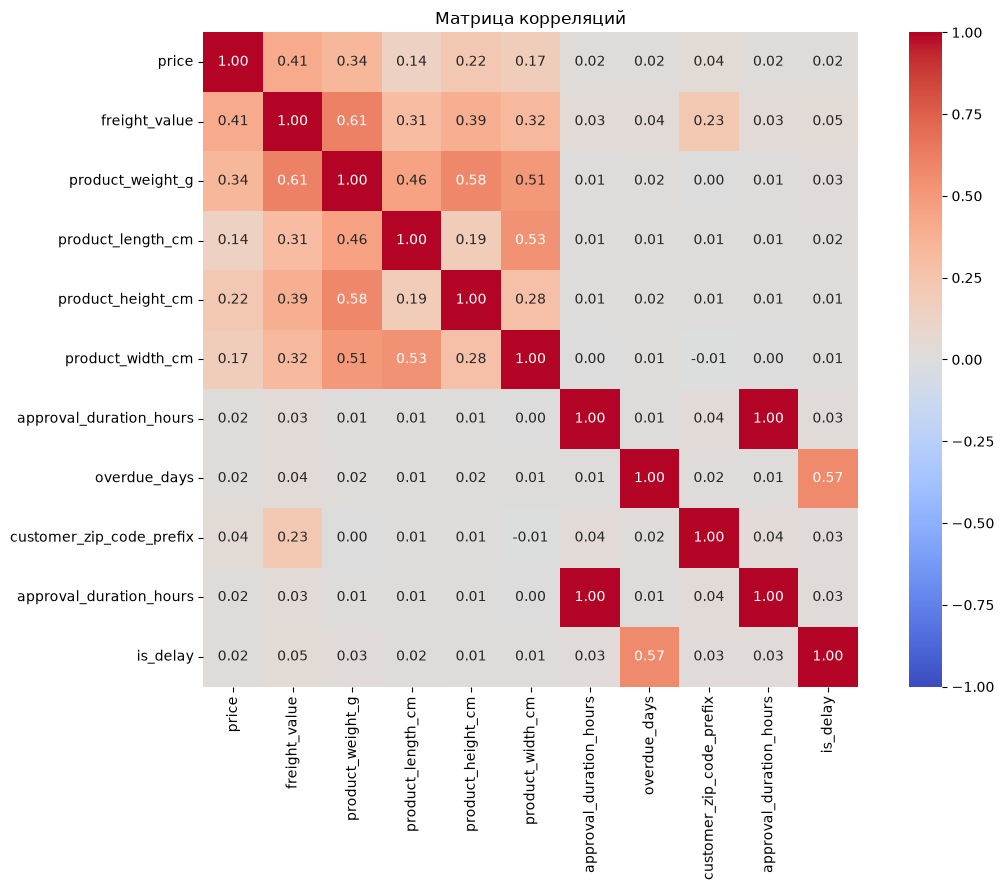

In [56]:
import seaborn as sns
import matplotlib.pyplot as plt

corr_matrix = baseline_data.corr(numeric_only=True)

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
)

plt.title("Матрица корреляций")
plt.tight_layout()
plt.show()

In [16]:
baseline_data.shape

baseline_data["overdue_days"].describe()

count    108643.000000
mean          0.689736
std           4.526126
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max         188.000000
Name: overdue_days, dtype: float64

In [17]:
X = baseline_data.drop("overdue_days", axis = 1)
y = baseline_data["overdue_days"]

In [18]:
from sklearn.model_selection import train_test_split

In [19]:
X_train, X_other, y_train, y_other = train_test_split(X, y, test_size=0.4, random_state= SEED)
X_val, X_test, y_val, y_test = train_test_split(X_other, y_other, test_size=0.5, random_state= SEED)

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

cat_cols = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", sparse_output=True),
            cat_cols,
        )
    ],
    remainder="passthrough",
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_val_encoded = preprocessor.transform(X_val)
X_test_encoded = preprocessor.transform(X_test)

print(X_train_encoded.shape)
print(X_val_encoded.shape)

(65185, 107)
(21729, 107)


In [21]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import root_mean_squared_error

from sklearn.linear_model import LinearRegression
baseline = DummyRegressor(strategy="mean")
lr = LinearRegression()
lr.fit(X_train_encoded, y_train)

baseline.fit(X_train, y_train)

lr_pred = lr.predict(X_val_encoded)
dummy_pred = baseline.predict(X_val)
dummy_mae = mean_absolute_error(y_val, dummy_pred)
dummy_rmse = root_mean_squared_error(y_val, dummy_pred)

lr_mae = mean_absolute_error(y_val, lr_pred)
lr_rmse = root_mean_squared_error(y_val, lr_pred)

print(f"Predicted delay for every order: {baseline.constant_.item():.2f} days")
print(f" dummy MAE: {dummy_mae:.2f} | lr MAE{lr_mae:.2f}")
print(f" dummy RMSE: {dummy_rmse:.2f} | lr RMSE {lr_rmse:.2f} ")

Predicted delay for every order: 0.68 days
 dummy MAE: 1.30 | lr MAE1.27
 dummy RMSE: 4.69 | lr RMSE 4.67 


In [23]:
from xgboost import XGBRegressor
# from xgboost import Rand
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

xgb = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    eval_metric="rmse",
    early_stopping_rounds=50,
    random_state=42,
    n_jobs=-1,
)

xgb.fit(
    X_train_encoded,
    y_train,
    eval_set=[(X_val_encoded, y_val)],
    verbose=100,
)

[0]	validation_0-rmse:4.69291
[69]	validation_0-rmse:4.69793


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",50
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'rmse'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [24]:
train_predictions = xgb.predict(X_train_encoded)
val_predictions = xgb.predict(X_val_encoded)

for name, actual, predicted in [
    ("Train", y_train, train_predictions),
    ("Validation", y_val, val_predictions),
]:
    mae = mean_absolute_error(actual, predicted)
    rmse = root_mean_squared_error(actual, predicted)

    print(f"{name}: MAE {mae:.2f} | RMSE {rmse:.2f}")

print(f"Best boosting round: {xgb.best_iteration + 1}")

Train: MAE 1.25 | RMSE 4.38
Validation: MAE 1.28 | RMSE 4.68
Best boosting round: 20


In [25]:
print("Original features:")
print(X_train.columns.tolist())

print("\nEncoded shape:")
print(X_train_encoded.shape)

print("\nTraining target distribution:")
print(y_train.describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

Original features:
['price', 'freight_value', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'approval_duration_hours', 'product_category_name', 'customer_state']

Encoded shape:
(65185, 107)

Training target distribution:
count    65185.000000
mean         0.680755
std          4.481057
min          0.000000
50%          0.000000
90%          0.000000
95%          3.000000
99%         18.000000
max        181.000000
Name: overdue_days, dtype: float64


In [28]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=10,
    max_features=0.8,
    criterion="squared_error",
    random_state=42,
    n_jobs=-1,
)

rf.fit(X_train_encoded, y_train)

train_predictions = rf.predict(X_train_encoded)
val_predictions = rf.predict(X_val_encoded)

for name, actual, predicted in [
    ("Train", y_train, train_predictions),
    ("Validation", y_val, val_predictions),
]:
    mae = mean_absolute_error(actual, predicted)
    rmse = root_mean_squared_error(actual, predicted)
    

    print(f"{name}: MAE {mae:.2f} | RMSE {rmse:.2f}")

Train: MAE 1.19 | RMSE 4.24
Validation: MAE 1.27 | RMSE 4.67


In [99]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

xgb_rf = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=1,          # One boosting round
    num_parallel_tree=300,  # 300 trees in that round
    learning_rate=1.0,
    max_depth=8,
    subsample=0.8,
    colsample_bynode=0.8,
    tree_method="hist",
    random_state=42,
    n_jobs=-1,
)

xgb_rf.fit(X_train_encoded, y_train)

for name, X_part, y_part in [
    ("Train", X_train_encoded, y_train),
    ("Validation", X_val_encoded, y_val),
]:
    predictions = xgb_rf.predict(X_part)

    mae = mean_absolute_error(y_part, predictions)
    rmse = root_mean_squared_error(y_part, predictions)

    print(f"{name}: MAE {mae:.2f} | RMSE {rmse:.2f}")

Train: MAE 1.18 | RMSE 4.04
Validation: MAE 1.25 | RMSE 4.70
